# Pérdida esperada de una cuenta: estructura de plazos, pérdida dado el incumplimiento, exposición y descuento

**Pregunta:** ¿Cuánto le cuesta a un banco un préstamo en pérdida crediticia esperada durante los próximos 12 meses y durante toda su vida, y por qué la cifra de vida completa es varias veces la de 12 meses?

- **Nivel:** 1, Fundamentos
- **Requisitos previos:** tema 01 (primeros pasos), notebooks 01 y 02
- **Tiempo de lectura:** unos 35 minutos

## Objetivos

Al terminar este notebook puedes:

- construir la supervivencia, la probabilidad marginal y la acumulada de incumplimiento a partir de una tasa de riesgo, y volver desde cualquiera de las otras dos al misma tasa de riesgo;
- escribir la pérdida crediticia esperada (PCE) de una cuenta como una suma de pérdidas marginales descontadas, y leer la PCE a 12 meses y la PCE de vida completa como la misma suma sobre dos horizontes;
- explicar por qué un préstamo que también puede prepagarse tiene una incidencia de incumplimiento menor que la que sugiere su tasa de riesgo de incumplimiento, y por qué la PD de vida completa de Contraste igual trata el prepago como censura;
- enunciar la convención de descuento (a mitad del período, a la tasa de interés efectiva original) y medir qué cambia, frente a una tasa libre de riesgo que IFRS 9 no permite;
- leer cómo crece la razón entre la PCE de vida completa y la de 12 meses de una cuenta con el plazo de su segmento.

## Preparación

Instala una vez el entorno fijado, en un entorno virtual, con el comando de siempre:

```bash
pip install -r notebooks/requirements.txt
```

o solo los paquetes que usa este notebook, con las mismas versiones exactas:

```bash
pip install riskvalidation==1.0.1 numpy==2.4.6 scipy==1.18.1 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` en Windows) construye `.venv-notebooks` por ti. La celda siguiente importa los paquetes e imprime sus versiones.

In [1]:
# Importar las herramientas e imprimir las versiones con que corren, para compararlas con notebooks/requirements.txt
import importlib.metadata as md
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
for name in ("riskvalidation", "numpy", "scipy", "matplotlib"):
    print(name, md.version(name))

riskvalidation 1.0.1
numpy 2.4.6
scipy 1.18.1
matplotlib 3.11.2


## Datos

Los datos son el caso C06 (PD de vida completa tipo hipotecario, etapas y PCE de IFRS 9) tal como Contraste lo versiona, a la fecha de reporte 2008-12-31. Los préstamos son los préstamos 7(a) a pequeñas empresas de la Administración de Pequeños Negocios de EE. UU. (SBA), el gemelo público del caso hipotecario (Obras del Gobierno de EE. UU., clase de licencia `mirror-allowed`; no se usan los datos de Freddie Mac, falta la cuenta del propietario). El flujo de cálculo ajustó tres peldaños de PD de vida completa con los préstamos conocidos a la fecha de reporte, los proyectó bajo tres escenarios macroeconómicos y versionó el resultado.

- **Archivos que se leen:** `data/derived/C06/rd-2008-12.json` para los ajustes, los horizontes y las estructuras de plazos (`outputs.term_structures`), y `data/derived/C06/models-rd-2008-12.json` para la pérdida dado el incumplimiento de cada segmento (`fit.lgd.segments`).
- **Lo que los archivos no tienen:** el saldo y la tasa de interés de una cuenta. La exposición y la tasa que se usan abajo son por eso **insumos declarados de esta lección**, rotulados como tales; la curva de PD y la pérdida dado el incumplimiento son las versionadas.

La celda siguiente carga ambos archivos e imprime la versión del motor que los calculó junto a la versión instalada ahora.

In [2]:
# Cargar el artefacto y el archivo de modelos del caso C06; el notebook está tres carpetas bajo la raíz del repositorio
from riskvalidation.provisions import ecl as ecl_engine, term_structure as tsm

ROOT = Path("../../..").resolve()
DERIVED = ROOT / "data" / "derived" / "C06"
case = json.loads((DERIVED / "rd-2008-12.json").read_text(encoding="utf-8"))
models = json.loads((DERIVED / "models-rd-2008-12.json").read_text(encoding="utf-8"))
out = case["outputs"]
print("motor que calculó el artefacto:", case["provenance"]["riskvalidation_version"])
print("motor instalado ahora:", md.version("riskvalidation"))
print("fecha de reporte:", out["reporting_date"], "| moneda:", out["currency"])
print("meses por período:", out["period_months"])

motor que calculó el artefacto: 1.0.1
motor instalado ahora: 1.0.1
fecha de reporte: 2008-12-31 | moneda: USD
meses por período: 3


## Método

El motor de Contraste enuncia la estructura de plazos y la PCE con las identidades de IFRS 9 tal como las escribe la literatura de análisis de supervivencia (Botha y Verster, 2025, ecuaciones 6 a 10). Para los períodos $t = 1, \dots, T$ posteriores a la fecha de reporte, con $h(t)$ la probabilidad de incumplir en el período $t$ dado que se sobrevive hasta su inicio (la tasa de riesgo discreto):

$$S(t) = \prod_{u=1}^{t}\bigl(1 - h(u)\bigr), \qquad q(t) = S(t-1)\,h(t), \qquad F(t) = \sum_{u=1}^{t} q(u) = 1 - S(t), \qquad h(t) = \frac{q(t)}{S(t-1)}$$

Aquí $S$ es la supervivencia, $q$ la probabilidad incondicional (marginal) de incumplimiento del período, $F$ la PD acumulada y $S(0) = 1$. La PCE de una cuenta en un escenario es la suma de las pérdidas marginales descontadas (GPPC 2016, sección 2.1.1.2; IFRS 9 B5.5.28 y B5.5.43 a B5.5.44):

$$\mathrm{PCE}(T) = \sum_{t=1}^{T} q(t)\; \mathrm{PDI}(t)\; \mathrm{EAD}(t)\; \mathrm{FD}(t), \qquad \mathrm{FD}(t) = (1 + r)^{-\delta(t)/12}$$

con $r$ la tasa de interés efectiva (TIE) original y $\delta(t)$ los meses desde la fecha de reporte hasta la fecha de pérdida supuesta del período $t$: el punto medio del período en la convención documentada de Contraste, el final del período en la alternativa. $T$ es 12 meses para la PCE a 12 meses (Etapa 1) y la vida esperada para la PCE de vida completa (Etapa 2). La norma fija el objetivo, no la fórmula, y la tasa de descuento es la TIE, nunca una tasa libre de riesgo (IFRS 9 B5.5.44).

Cada paso siguiente llama al motor (`riskvalidation.provisions`) sobre los datos anteriores y dibuja o tabula lo que devuelve. Los insumos de la lección que el archivo no contiene (el saldo, la tasa de interés y una tasa de riesgo de prepago) se declaran en mayúsculas donde entran.

### Paso 1: la estructura de plazos de un segmento

El artefacto guarda, para cada segmento y escenario, la tasa de riesgo por trimestre. Tomamos la curva ponderada por escenarios del segmento de préstamos con plazo de más de 20 años, la curva que lleva un préstamo largo, y entregamos su tasa de riesgo a `from_hazard`, que devuelve la supervivencia, la PD marginal y la acumulada de las identidades anteriores. La celda imprime cuatro trimestres y dibuja la estructura: barras para la PD marginal con la PD acumulada como línea, y al lado la supervivencia.

mes   3 | h 0.001589 | q 0.001589 | F 0.001589 | S 0.998411
mes  12 | h 0.001548 | q 0.001541 | F 0.006188 | S 0.993812
mes  60 | h 0.001166 | q 0.001134 | F 0.028451 | S 0.971549
mes 120 | h 0.000698 | q 0.000667 | F 0.045763 | S 0.954237


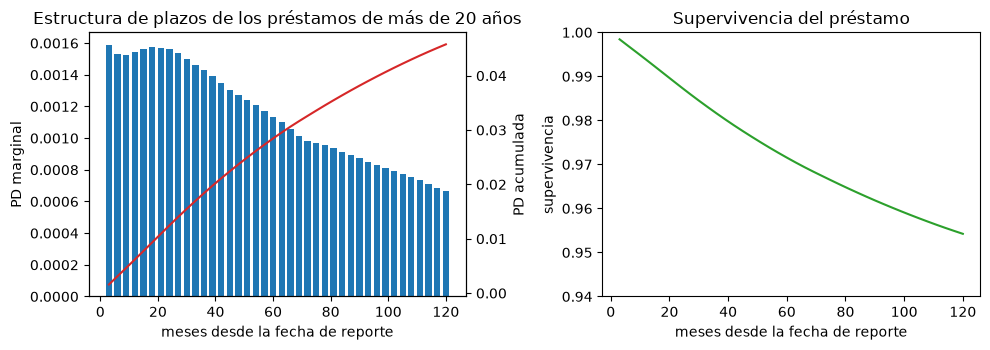

In [3]:
# Reconstruir la estructura de plazos de un segmento desde su tasa de riesgo, imprimir cuatro trimestres y dibujarla
SEGMENT = "term-gt-240"
rows = {(r["scenario_id"], r["segment_id"]): r for r in out["term_structures"]}
curve = rows[("weighted", SEGMENT)]
months = np.array(curve["months"])
ts = tsm.from_hazard(np.array(curve["hazard"]), months)
for k in (0, 3, 19, 39):
    h, q_, f_, s_ = ts.hazard[k], ts.marginal[k], ts.cumulative[k], ts.survival[k]
    print(f"mes {int(months[k]):3d} | h {h:.6f} | q {q_:.6f} | F {f_:.6f} | S {s_:.6f}")

fig, (left, right) = plt.subplots(1, 2, figsize=(10, 3.6))
left.bar(months, ts.marginal, width=2.2, color="tab:blue", label="PD marginal")
left.set_xlabel("meses desde la fecha de reporte")
left.set_ylabel("PD marginal")
twin = left.twinx()
twin.plot(months, ts.cumulative, color="tab:red", label="PD acumulada")
twin.set_ylabel("PD acumulada")
left.set_title("Estructura de plazos de los préstamos de más de 20 años")
right.plot(months, ts.survival, color="tab:green")
right.set_ylim(0.94, 1.0)
right.set_xlabel("meses desde la fecha de reporte")
right.set_ylabel("supervivencia")
right.set_title("Supervivencia del préstamo")
fig.tight_layout()
plt.show()

La PD marginal cambia despacio: cerca de 0,16% en el primer trimestre y bajando suavemente hacia 0,07% en el tope de diez años. Como cada trimestre suma un poco, la PD acumulada sube casi en línea recta hasta cerca de 4,6% al mes 120, y la supervivencia, dibujada a la derecha con un eje ampliado, cae en la misma cantidad. Un trimestre de este préstamo es un hecho menor. Su peso viene de sumar cuarenta trimestres así, que es lo que la PCE del paso 6 convierte en dinero.

### Paso 2: tres puertas de entrada, una sola tasa de riesgo

Un banco rara vez parte de una tasa de riesgo. Una tarjeta de puntaje o una tabla de cosechas entrega la PD acumulada desde la fecha de reporte, y una curva regulatoria entrega la PD marginal. `from_marginal` y `from_cumulative` las reciben y devuelven la misma estructura, con $h(t) = q(t)/S(t-1)$. La celda entrega a cada puerta la curva del paso 1 e imprime cuánto se aleja la tasa de riesgo que devuelven del que devolvió la primera puerta. Luego entrega a `from_cumulative` una curva que deja de subir, que no es una PD acumulada, para ver cómo el motor la rechaza.

In [4]:
# Recuperar la tasa de riesgo por la puerta marginal y por la acumulada, y ver qué rechaza el motor
from_marginal = tsm.from_marginal(ts.marginal, months)
from_cumulative = tsm.from_cumulative(ts.cumulative, months)
gap_marginal = np.abs(from_marginal.hazard - ts.hazard).max()
gap_cumulative = np.abs(from_cumulative.hazard - ts.hazard).max()
print("mayor diferencia de la tasa de riesgo por la PD marginal:", f"{gap_marginal:.1e}")
print("mayor diferencia de la tasa de riesgo por la PD acumulada:", f"{gap_cumulative:.1e}")
broken = ts.cumulative.copy()
broken[5] = broken[4]
try:
    tsm.from_cumulative(broken, months)
except ValueError as error:
    print("una PD acumulada que no sube se rechaza con", type(error).__name__)

mayor diferencia de la tasa de riesgo por la PD marginal: 4.3e-19
mayor diferencia de la tasa de riesgo por la PD acumulada: 3.0e-18
una PD acumulada que no sube se rechaza con ValueError


Ambas puertas devuelven la tasa de riesgo del paso 1 hasta la precisión de la aritmética de punto flotante, de modo que las tres representaciones son un solo objeto visto de tres maneras y elegir la puerta depende de lo que el banco tenga a mano. El rechazo importa tanto como eso: una entrada que rompe las reglas de una probabilidad acumulada se convierte en un error con nombre, y nunca en una PCE equivocada que alguien deba encontrar después en un informe.

### Paso 3: la PD en una ventana

La PCE a 12 meses necesita la PD del primer año, y la clasificación en etapas del notebook 02 necesita la PD del resto de la vida dado que se sobrevive al primer aniversario. La función `forward_pd` del motor devuelve la PD condicional en $(a, b]$ dado que se sobrevive hasta $a$, $\mathrm{PD}(a, b) = (S(a) - S(b))/S(a)$. La celda pide el primer año, los meses 12 a 120 y la vida completa.

In [5]:
# Pedir la PD en tres ventanas: el primer año, el resto de la vida y la vida completa
first_year = float(tsm.forward_pd(ts, 0, 12))
remaining_life = float(tsm.forward_pd(ts, 12, 120))
whole_life = float(tsm.forward_pd(ts, 0, 120))
print("PD de los primeros 12 meses:", round(first_year, 6))
print("PD de los meses 12 a 120 dado que se sobrevive al mes 12:", round(remaining_life, 6))
print("PD de la vida completa:", round(whole_life, 6))

PD de los primeros 12 meses: 0.006188
PD de los meses 12 a 120 dado que se sobrevive al mes 12: 0.039822
PD de la vida completa: 0.045763


El primer año lleva 0,62% de probabilidad de incumplimiento y los nueve años restantes llevan 3,98%, unas seis veces más, de modo que un préstamo medido a doce meses y uno medido a lo largo de su vida son magnitudes distintas aun antes de que entren la pérdida o el descuento. Las tres ventanas se componen: sobrevivir el primer año y luego el resto devuelve la PD de la vida completa, 4,58%.

### Paso 4: el prepago como salida competidora

Un préstamo sale del libro por incumplimiento o por pago anticipado. Si el pago anticipado es posible, el préstamo deja de estar expuesto en los períodos posteriores, y por eso la incidencia de incumplimiento es menor que la de una tasa de riesgo de incumplimiento que lo ignora. Con tasas de riesgo por causa $h^D$ y $h^P$, `competing_risks` del motor calcula $S^{\mathrm{all}}(t) = \prod_u (1 - h^D(u) - h^P(u))$ y la incidencia de incumplimiento $q^D(t) = S^{\mathrm{all}}(t-1)\,h^D(t)$ (Botha y Verster, 2025; IFRS 9 B5.5.51 pide el efecto de los prepagos esperados). El caso C06 de Contraste no lleva una tasa de riesgo de prepago: el hallazgo versionado `F-PREPAYMENT` trata el prepago como censura. Para mostrar el efecto, la celda agrega una tasa de riesgo **declarada e ilustrativa** de 1% por trimestre, que no es una estimación de Contraste.

incumplimiento acumulado, solo la tasa de riesgo de incumplimiento: 0.045763
incidencia acumulada de incumplimiento con prepago: 0.039038
probabilidad de salir del libro por cualquiera de las dos vías: 0.361945


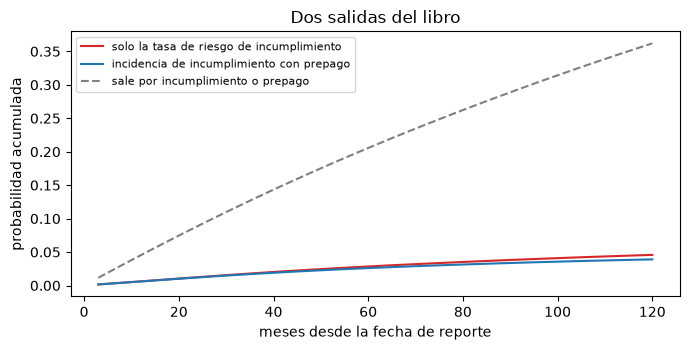

In [6]:
# Agregar una tasa de riesgo de prepago declarada a la de incumplimiento y comparar las tres curvas acumuladas
PREPAY_HAZARD = 0.01  # illustrative input of the lesson, per quarter
competing = tsm.competing_risks(ts.hazard, np.full(ts.hazard.shape, PREPAY_HAZARD), months)
leaves = 1.0 - competing.survival_all
print("incumplimiento acumulado, solo la tasa de riesgo de incumplimiento:", round(float(ts.cumulative[-1]), 6))
with_prepayment = competing.cumulative_default
print("incidencia acumulada de incumplimiento con prepago:", round(float(with_prepayment[-1]), 6))
print("probabilidad de salir del libro por cualquiera de las dos vías:", round(float(leaves[-1]), 6))

fig, ax = plt.subplots(figsize=(7, 3.6))
ax.plot(months, ts.cumulative, color="tab:red", label="solo la tasa de riesgo de incumplimiento")
ax.plot(months, with_prepayment, color="tab:blue", label="incidencia de incumplimiento con prepago")
ax.plot(months, leaves, color="tab:grey", linestyle="--", label="sale por incumplimiento o prepago")
ax.set_xlabel("meses desde la fecha de reporte")
ax.set_ylabel("probabilidad acumulada")
ax.set_title("Dos salidas del libro")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

Las curvas roja y azul se separan despacio: con prepago, los préstamos que habrían caído en incumplimiento tarde muchas veces ya no están para hacerlo, y la incidencia acumulada de incumplimiento al mes 120 es 3,90% frente a 4,58%. La curva punteada es la lección del paso. Más de un tercio del libro sale por una de las dos vías, y la probabilidad de salir no es la probabilidad de incumplir. C06 elige la censura, que queda del lado prudente de esta imagen.

### Paso 5: el factor de descuento

Cada pérdida se trae a la fecha de reporte a la tasa de interés efectiva original (TIE). `discount_factors` devuelve $(1 + r)^{-\delta/12}$ para cada cuenta y período. Con la convención de mitad del período, una pérdida del primer trimestre se descuenta 1,5 meses y no 3, porque se supone que el incumplimiento cae a mitad del trimestre. La tasa es un **insumo declarado** de 8% anual, porque el artefacto no guarda una tasa por cuenta. La celda imprime los cuatro primeros factores bajo ambas convenciones.

In [7]:
# Factores de descuento de una cuenta bajo las dos convenciones
EIR = np.array([0.08])  # illustrative input of the lesson, per year
df_mid = ecl_engine.discount_factors(EIR, months, "mid-period")[0]
df_end = ecl_engine.discount_factors(EIR, months, "end-of-period")[0]
print("mitad del período, cuatro primeros períodos:", np.round(df_mid[:4], 6))
print("fin del período, cuatro primeros períodos:", np.round(df_end[:4], 6))

mitad del período, cuatro primeros períodos: [0.990426 0.971552 0.953038 0.934876]
fin del período, cuatro primeros períodos: [0.980944 0.96225  0.943913 0.925926]


Los factores de mitad del período son algo mayores que los de fin del período, 0,9904 frente a 0,9809 en el primer trimestre, porque se supone la pérdida mes y medio más cerca. La diferencia es pequeña por trimestre y se repite cuarenta veces, de modo que el paso 7 mide qué hace con la PCE de vida completa.

### Paso 6: la PCE de una cuenta, a 12 meses y de vida completa

`ecl_scenario` evalúa $\sum_{t \le T} q\,\mathrm{LGD}\,\mathrm{EAD}\,\mathrm{DF}$ para un lote de cuentas. Le damos una cuenta: la PD marginal del paso 1, la pérdida dado el incumplimiento que el flujo de cálculo estimó para este segmento (`fit.lgd.segments`, una aproximación de severidad por castigo), una exposición de 100.000 USD (un insumo declarado de la lección, constante aquí; el flujo de cálculo la amortiza, ver `F-EAD-MODEL`), la tasa declarada y un horizonte. Un horizonte de 12 meses da la cifra de la Etapa 1 y la vida completa da la cifra de la Etapa 2. Pedir cada horizonte por turno dibuja cómo se acumula la PCE.

pérdida dado el incumplimiento del segmento: 0.532313
PCE a 12 meses, USD: 317.09 | PCE de vida completa, USD: 1799.23
PCE de vida completa sobre PCE a 12 meses: 5.674


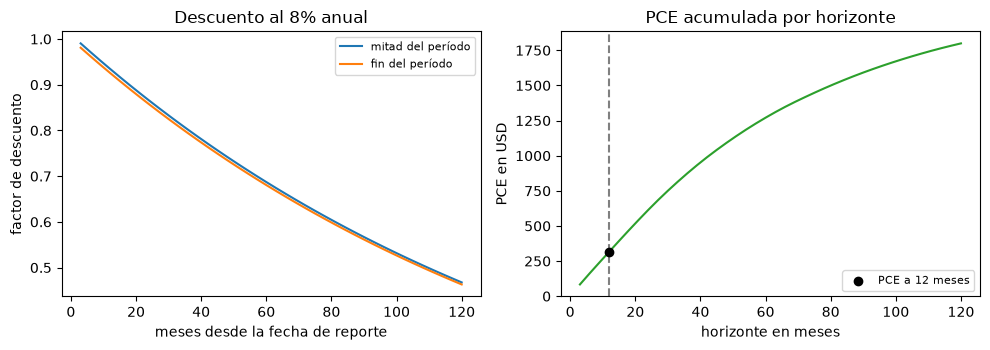

In [8]:
# Calcular la PCE a 12 meses y de vida completa de una cuenta y su acumulación por horizonte
lgd_by_segment = {s["segment_id"]: s["lgd"] for s in models["fit"]["lgd"]["segments"]}
lgd = lgd_by_segment[SEGMENT]
EAD = 100_000.0  # illustrative input of the lesson, constant over the life
q = ts.marginal[None, :]
ecl_12 = float(ecl_engine.ecl_scenario(q, lgd, EAD, EIR, months, 12, "mid-period")[0])
ecl_life = float(ecl_engine.ecl_scenario(q, lgd, EAD, EIR, months, int(months[-1]), "mid-period")[0])
build_up = [float(ecl_engine.ecl_scenario(q, lgd, EAD, EIR, months, int(h), "mid-period")[0]) for h in months]
print("pérdida dado el incumplimiento del segmento:", round(lgd, 6))
print("PCE a 12 meses, USD:", round(ecl_12, 2), "| PCE de vida completa, USD:", round(ecl_life, 2))
print("PCE de vida completa sobre PCE a 12 meses:", round(ecl_life / ecl_12, 3))

fig, (left, right) = plt.subplots(1, 2, figsize=(10, 3.6))
left.plot(months, df_mid, color="tab:blue", label="mitad del período")
left.plot(months, df_end, color="tab:orange", label="fin del período")
left.set_xlabel("meses desde la fecha de reporte")
left.set_ylabel("factor de descuento")
left.set_title("Descuento al 8% anual")
left.legend(fontsize=8)
right.plot(months, build_up, color="tab:green")
right.axvline(12, color="grey", linestyle="--")
right.scatter([12], [ecl_12], color="black", zorder=3, label="PCE a 12 meses")
right.set_xlabel("horizonte en meses")
right.set_ylabel("PCE en USD")
right.set_title("PCE acumulada por horizonte")
right.legend(fontsize=8)
fig.tight_layout()
plt.show()

Para una cuenta de 100.000 USD la PCE a 12 meses es 317,09 USD, 0,32% de la exposición, y la PCE de vida completa es 1.799,23 USD, 1,80%. El panel derecho muestra por qué difieren: la curva de acumulación es una suma corrida de aportes pequeños y casi iguales, la cifra a 12 meses es esa curva leída en el mes 12 y la cifra de vida completa es su final. Los factores de descuento del panel izquierdo doblan un poco la curva hacia abajo en horizontes tardíos sin cambiar su forma.

### Paso 7: qué cambian la convención y la tasa

Dos decisiones mueven la PCE sin mover el riesgo de crédito: la convención de descuento y la tasa. IFRS 9 B5.5.44 fija la tasa en la TIE. Una tasa libre de riesgo es menor que la TIE, descuenta menos y da una PCE mayor, que no es la medida de la norma. La celda recalcula la PCE de vida completa con la convención de fin del período y con una tasa libre de riesgo de 2% anual, un insumo declarado de la lección, e imprime cada variación respecto de la configuración del paso 6.

In [9]:
# Recalcular la PCE de vida completa con la otra convención y con una tasa libre de riesgo
RISK_FREE = np.array([0.02])  # illustrative input of the lesson, per year
life = int(months[-1])
end_of_period = float(ecl_engine.ecl_scenario(q, lgd, EAD, EIR, months, life, "end-of-period")[0])
risk_free = float(ecl_engine.ecl_scenario(q, lgd, EAD, RISK_FREE, months, life, "mid-period")[0])
print("PCE de vida completa, mitad del período a la TIE (la configuración), USD:", round(ecl_life, 2))
print("PCE de vida completa, fin del período a la TIE, USD:", round(end_of_period, 2))
print("variación:", round(end_of_period / ecl_life - 1.0, 5))
print("PCE de vida completa, mitad del período a una tasa libre de riesgo, USD:", round(risk_free, 2))
print("variación:", round(risk_free / ecl_life - 1.0, 5))

PCE de vida completa, mitad del período a la TIE (la configuración), USD: 1799.23
PCE de vida completa, fin del período a la TIE, USD: 1782.0
variación: -0.00957
PCE de vida completa, mitad del período a una tasa libre de riesgo, USD: 2243.83
variación: 0.24711


La convención es una decisión de segundo orden: llevar la pérdida al final del trimestre baja la PCE de vida completa en 0,96%. La tasa es de primer orden: una tasa libre de riesgo de 2% la sube en 24,7%. Una cifra que se mueve en una cuarta parte por una tasa de descuento que la norma no permite no sería una medida de riesgo de crédito, y por eso la tasa de descuento forma parte de la configuración documentada y no es un parámetro libre.

### Paso 8: los cuatro segmentos y lo que hace el horizonte

El mismo cálculo sobre los cuatro segmentos del modelo versionado muestra cuánta parte de la pérdida de vida completa cae en el primer año. Un préstamo corto tiene la mayor parte de su pérdida dentro de 12 meses. Un préstamo largo tiene una PCE a 12 meses pequeña y una PCE de vida completa varias veces mayor. Esa razón es el salto que da un préstamo cuando pasa de la Etapa 1 a la Etapa 2, el acantilado del notebook 02. Cada segmento usa su propia curva versionada y su pérdida dado el incumplimiento, con la exposición y la tasa de esta lección.

hasta 5 años     | pérdida dado el incumplimiento 1.0000 | razón  2.21
                 | 12 meses   7932.85 | vida completa  17498.45
5 a 10 años      | pérdida dado el incumplimiento 1.0000 | razón  3.79
                 | 12 meses   3153.63 | vida completa  11964.31
10 a 20 años     | pérdida dado el incumplimiento 0.6737 | razón  5.05
                 | 12 meses    863.06 | vida completa   4361.50
más de 20 años   | pérdida dado el incumplimiento 0.5323 | razón  5.67
                 | 12 meses    317.09 | vida completa   1799.23


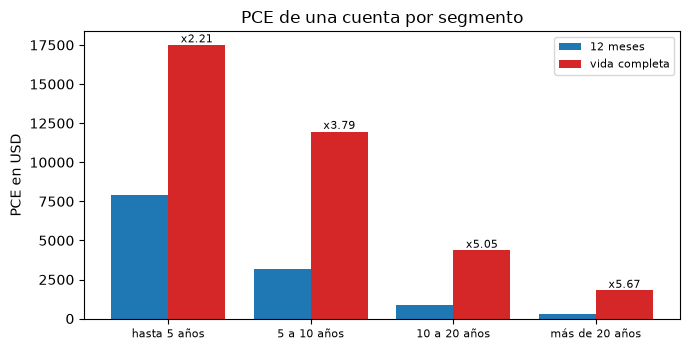

In [10]:
# Calcular la PCE a 12 meses y de vida completa de una cuenta en cada uno de los cuatro segmentos
labels = {
    "term-le-60": "hasta 5 años",
    "term-61-120": "5 a 10 años",
    "term-121-240": "10 a 20 años",
    "term-gt-240": "más de 20 años",
}
by_segment = {}
for segment in labels:
    c = rows[("weighted", segment)]
    m = np.array(c["months"])
    marginal = tsm.from_hazard(np.array(c["hazard"]), m).marginal[None, :]
    lgd_s = lgd_by_segment[segment]
    e12 = float(ecl_engine.ecl_scenario(marginal, lgd_s, EAD, EIR, m, 12)[0])
    elife = float(ecl_engine.ecl_scenario(marginal, lgd_s, EAD, EIR, m, int(m[-1]))[0])
    by_segment[segment] = (e12, elife)
    print(f"{labels[segment]:16s} | pérdida dado el incumplimiento {lgd_s:.4f} | razón {elife / e12:5.2f}")
    print(f"{'':16s} | 12 meses {e12:9.2f} | vida completa {elife:9.2f}")

fig, ax = plt.subplots(figsize=(7, 3.6))
x = np.arange(len(labels))
ax.bar(x - 0.2, [v[0] for v in by_segment.values()], width=0.4, color="tab:blue", label="12 meses")
ax.bar(x + 0.2, [v[1] for v in by_segment.values()], width=0.4, color="tab:red", label="vida completa")
for k, (e12_k, elife_k) in enumerate(by_segment.values()):
    ax.text(k + 0.2, elife_k, f"x{elife_k / e12_k:.2f}", ha="center", va="bottom", fontsize=8)
ax.set_xticks(x)
ax.set_xticklabels(list(labels.values()), fontsize=8)
ax.set_ylabel("PCE en USD")
ax.set_title("PCE de una cuenta por segmento")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

Los dos segmentos más cortos llevan una pérdida dado el incumplimiento de 1,0, el aproximación de severidad por castigo del flujo de cálculo, que tiene un sesgo al alza (hallazgo `F-LGD-PROXY`), de modo que sus cifras absolutas son las prudentes; la comparación que importa es la razón. Crece con el plazo, de 2,21 para préstamos de hasta cinco años a 5,67 sobre veinte, porque un préstamo largo conserva la mayor parte de su exposición y de su probabilidad de incumplimiento más allá del primer aniversario.

## Resultados

**Respuesta:** Un préstamo del segmento de más de 20 años cuesta 317,09 USD de pérdida crediticia esperada a 12 meses y 1.799,23 USD a lo largo de toda su vida, 5,67 veces más, porque la probabilidad de incumplimiento de los primeros 12 meses es 0,0062 mientras que la de los nueve años restantes es 0,0398, de modo que la mayor parte de la pérdida de vida completa cae después del primer aniversario.

- **Una tasa de riesgo, tres puertas.** La supervivencia, la PD marginal y la acumulada del segmento de préstamos largos son un solo objeto: entrar por la PD marginal o por la acumulada devuelve la tasa de riesgo del paso 1 con una diferencia menor que 1e-17, y una PD acumulada que deja de subir se rechaza con un `ValueError` antes de que pueda convertirse en una PCE equivocada.
- **El primer año es una parte pequeña de un préstamo largo.** La PD de los primeros 12 meses es 0,0062, la PD de los meses 12 a 120 dado que se sobrevive al mes 12 es 0,0398 y la vida completa lleva 0,0458. Por eso un préstamo que pasa de la Etapa 1 a la Etapa 2 cambia tanto su medición.
- **El prepago importa y la PD de vida completa de Contraste no lo lleva.** Con una tasa de riesgo de prepago ilustrativa de 1% por trimestre, la incidencia acumulada de incumplimiento al mes 120 baja de 0,0458 a 0,0390 y 36% de los préstamos sale del libro por una de las dos vías. C06 trata el prepago como censura (hallazgo `F-PREPAYMENT`), así que en este punto su PCE de vida completa queda del lado prudente.
- **La PCE es una suma que se puede leer.** Para la cuenta de la lección la PCE a 12 meses es 317,09 USD (0,32% de la exposición) y la PCE de vida completa es 1.799,23 USD (1,80%).
- **Convención y tasa no son decisiones equivalentes.** La convención de fin del período baja la PCE de vida completa en 0,96%; una tasa libre de riesgo de 2% la sube en 24,7%, y por eso IFRS 9 fija la tasa en la TIE.
- **El efecto del horizonte depende del plazo.** La razón entre la PCE de vida completa y la de 12 meses es 2,21 para préstamos de hasta 5 años, 3,79 para 5 a 10 años, 5,05 para 10 a 20 años y 5,67 sobre 20 años.

Lo que este notebook no muestra: la exposición y la tasa son insumos de la lección, no datos del archivo, y el flujo de cálculo amortiza el saldo (hallazgo `F-EAD-MODEL`) donde la lección lo mantiene constante. La clasificación en etapas que decide cuál de las dos PCE lleva un préstamo es el notebook 02; la ponderación de los tres escenarios es el notebook 03.

## Resumen

- La supervivencia, la PD marginal y la acumulada son un solo objeto visto de tres maneras; el motor lo construye desde una tasa de riesgo, una PD marginal o una PD acumulada y rechaza las entradas inválidas.
- La PCE de una cuenta es la suma, sobre los períodos, de la PD marginal, la pérdida dado el incumplimiento, la exposición y el factor de descuento. La PCE a 12 meses y la de vida completa son la misma suma cortada en dos horizontes.
- El descuento es a la TIE original, a mitad del período por la configuración documentada de Contraste; la otra convención cambia la cifra en unas décimas de punto porcentual y una tasa libre de riesgo la cambia en una cuarta parte, sin cambiar el riesgo.
- Una salida competidora como el prepago baja la incidencia de incumplimiento y no es el complemento de la supervivencia; C06 registra su elección, la censura, como hallazgo.

**Qué probar después.** Cambia `PREPAY_HAZARD` a 0 y luego a 0,03 y observa la incidencia de incumplimiento; cambia `SEGMENT` a `term-le-60`. Luego sigue con el notebook 02, que decide cuál de las dos PCE lleva cada préstamo.

## Referencias

- IASB, IFRS 9 Instrumentos financieros (julio de 2014), tal como lo adopta el Reglamento (UE) 2016/2067 de la Comisión, párrafos 5.5 y B5.5, y las enmiendas a la IFRS 7, 35A a 35N. https://eur-lex.europa.eu/legal-content/EN/TXT/HTML/?uri=CELEX:32016R2067
- Botha, A. y Verster, T. (2025), Approaches for modelling the term-structure of default risk under IFRS 9: a tutorial using discrete-time survival analysis, ecuaciones 6 a 10. https://arxiv.org/abs/2507.15441
- GPPC (2016), The implementation of IFRS 9 impairment requirements by banks, 17 de junio de 2016, secciones 2.1.1, 2.7.2 y 2.8.1.2. https://www.globalpublicpolicycommittee.org/wp-content/uploads/2022/12/gppc-ifrs9-implementation-considerations-20160617.pdf